## Run SUMMA and MizuRoute ESP ##

Run the SUMMA and ESP models, with the model runs managed by Snakemake


### Write snakemake file ###

This block of code writes the snakemake file

In [2]:
config_file = "/Users/dcasson/GitHub/snow_dist/snakemake/config/ross_from_camille.yaml"

In [26]:
%%writefile ../rules/run_summa_distributed.smk

from pathlib import Path
import sys
import pandas as pd
import pysumma as ps

sys.path.append('../scripts/')
import ss_utils

include: "../rules/run_pysumma_base.smk"
include: "../rules/merge_restart_files.smk"
include: "../scripts/run_esp.smk"

rule run_summa_distributed:
    input:
        Path(config['summa_output_path'], f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
        

Overwriting ../rules/run_summa_distributed.smk


In [3]:
! snakemake -s ../rules/run_pysumma_base.smk --cores 8 --configfile {config_file} --nolock

Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                         count
------------------------  -------
merge_summa_output_files        1
run_mizuroute                   1
run_pysumma_base                1
run_summa_in_gru_chunks        52
total                          55

Select jobs to execute...

[Tue Feb  4 14:25:05 2025]
rule run_summa_in_gru_chunks:
    input: /Users/dcasson/Data/yukon_esp/ross_from_camille/model/settings/SUMMA/fileManager.txt
    output: /Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/summa_output/Ross_base_G109-111_timestep.nc
    log: logs/summa_Ross_base_G109-111.log
    jobid: 38
    reason: Missing output files: /Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/summa_output/Ross_base_G109-111_timestep.nc
    wildcards: gru_chunk=G109-111
    resources: tmpdir=/var/folders/w4/qfhdls_x5jj48jhgnhtfv1lm0000gn/T

[Tue Feb  4 14:25:05 2025]
rule run_s

In [2]:
# Output dag
! snakemake -s ../rules/run_summa_distributed.smk --configfile {config_file} --nolock --dag | dot -Tpng > ../run_summa_distributed.png
# Display output dag
from IPython.display import Image
Image("../run_summa_distributed.png")

Error: Snakefile "../rules/run_summa_distributed.smk" not found.


In [5]:
%%writefile ../rules/run_pysumma_base.smk
"""
Snakemake file to run the base SUMMA simulations.

The model simulation is chunked by GRU to allow for parallelization on a cluster.

The chunks of GRUs are defined by the user.
"""

from pathlib import Path
import sys
import pandas as pd
import pysumma as ps
import shutil

sys.path.append('../scripts/')
import ss_utils
import model_run_utils

# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
summa_cold_state_name = config['summa_cold_state']
summa_cold_state_path = Path(config['summa_settings_path'], summa_cold_state_name)
summa_restart_path.mkdir(parents=True, exist_ok=True)

attributes_nc = Path(config['summa_settings_path'], config['attributes_nc'])
file_manager = Path(config['file_manager'])
summa_exe = Path(config['summa_exe'])
sim_start_time = config['model_start_time']
sim_end_time = config['model_end_time']
case_name = config['case_name']


# Read mizuroute configuration
mizuroute_exe = config['mizuroute_exe']
mizuroute_output_path = Path(config['mizuroute_output_path'])
control_file_base = Path(config['mizuroute_settings_path'], config['mizuroute_control_file'])
mizuroute_cold_state_name = config['mizuroute_cold_state']
mizuroute_cold_state_path = Path(config['mizuroute_settings_path'], config['mizuroute_cold_state'])
ancil_dir = config['mizuroute_settings_path']
mizuroute_restart_path = Path(config['mizuroute_restart_path'])
mizuroute_restart_path.mkdir(parents=True, exist_ok=True)

# Calculate the number of GRUs from the attributes_nc and generate chunk strings
num_grus = ss_utils.calc_num_grus(attributes_nc)
gru_chunks = ss_utils.generate_gru_start_and_count(
    num_grus, chunk_size=config['gru_chunk_size']
)

# Copy summa state file to restart directory
shutil.copy(summa_cold_state_path, Path(summa_restart_path, summa_cold_state_name))
shutil.copy(mizuroute_cold_state_path, Path(mizuroute_restart_path, mizuroute_cold_state_name))

# Run the base SUMMA simulation
rule run_pysumma_base:
    input:
        Path(summa_output_path, f"{config['case_name']}_{config['run_suffix']}_timestep.nc"),
        Path(mizuroute_output_path, f"{config['case_name']}_{config['run_suffix']}_routed.nc")

# Run SUMMA simulations for each GRU chunk
rule run_summa_in_gru_chunks:
    wildcard_constraints:
        gru_chunk='|'.join(gru_chunks)
    input:
        file_manager = file_manager
    output:
        summa_chunked_output = temp(Path(summa_output_path, f"{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}_timestep.nc"))
    params:
        summa_exe = summa_exe,
        gru_start = lambda wildcards: ss_utils.extract_gru_int(wildcards.gru_chunk),
        gru_count = config['gru_chunk_size']
    log:
        log_file =  f"logs/summa_{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}.log"
    run:
        sim = ps.Simulation(params.summa_exe, input.file_manager)

        sim_config = {
            'manager': {
                'simStartTime': sim_start_time,
                'simEndTime': sim_end_time,
                #'statePath': str(summa_restart_path) + '/',
                'outputPath': str(summa_output_path) + '/'
            }
        }
       
        # Set the configuration
        sim.apply_config(sim_config)

        # Set the last file name for the GRU chunking
        if params.gru_start + params.gru_count > num_grus:
            params.gru_count = num_grus - params.gru_start + 1

        sim.run(
            run_suffix=config['run_suffix'],
            startGRU=params.gru_start,
            countGRU=params.gru_count,
            write_config=False,
            write_manager=True,
            freq_restart='m'
        )

        print(f"SUMMA simulation for GRUs {params.gru_start} to {params.gru_start + params.gru_count - 1} finished with {sim.status}.")

# Merge SUMMA output files
rule merge_summa_output_files:
    input:
        chunked_output_files = expand(
            Path(summa_output_path, f"{config['case_name']}_{config['run_suffix']}_{{gru_chunk}}_timestep.nc"),
            gru_chunk=gru_chunks
        )
    output:
        merged_output_file = Path(summa_output_path, f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    run:
        print(f"Merging SUMMA output files into {output.merged_output_file}.")
        ss_utils.merge_netcdf_output(input.chunked_output_files, output.merged_output_file)
# Run MizuRoute
rule run_mizuroute:
    input:
        mizuroute_input = Path(summa_output_path, f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    output:
        mizuroute_output = Path(mizuroute_output_path, f"{config['case_name']}_{config['run_suffix']}_routed.nc")
    params:
        mizuroute_exe=mizuroute_exe,
        mizuroute_input_path=summa_output_path,
        mizuroute_output_path=mizuroute_output_path,
        control_file_base=control_file_base,
        case_name=case_name,
        ancil_dir=ancil_dir,
        sim_start_time=sim_start_time,
        sim_end_time=sim_end_time,
        output_path=mizuroute_output_path,
        restart_dir=mizuroute_restart_path
    run:
        #Set MizuRoute control file
        control_file_case = Path(params.mizuroute_output_path,f"{case_name}_mizuroute.control")
        #Set MizuRoute input file
        mizuroute_input_file = Path(input.mizuroute_input).name
        # Set timing
        start_time_pd = pd.to_datetime(params.sim_start_time)
        end_time_pd = pd.to_datetime(params.sim_end_time) - pd.Timedelta('1h')
        start_time_for_file_name=start_time_pd.strftime('%Y-%m-%d-%H')
        #Update control file
        model_run_utils.update_mizuroute_run_settings(
            input_control_file = params.control_file_base,
            output_control_file = control_file_case,
            input_summa_file = mizuroute_input_file,
            input_mizuroute_state = mizuroute_cold_state_name,
            case_name = params.case_name,
            sim_start = start_time_pd,
            sim_end = end_time_pd,
            ancil_dir = params.ancil_dir,
            input_dir = params.mizuroute_input_path,
            output_dir = params.mizuroute_output_path,
            restart_dir = params.restart_dir
        )

        #Run MizuRoute
        model_run_utils.run_mizuroute(params.mizuroute_exe, control_file_case)
        #Rename output file
        generated_file = Path(params.output_path,f"{params.case_name}.h.{start_time_for_file_name}000.nc")
        generated_file.rename(output.mizuroute_output)

Overwriting ../rules/run_pysumma_base.smk


In [8]:
! snakemake -s ../rules/run_pysumma_base.smk --cores 8 --configfile {config_file} --nolock --quiet

Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                         count
------------------------  -------
merge_summa_output_files        1
run_mizuroute                   1
run_pysumma_base                1
run_summa_in_gru_chunks        52
total                          55

Select jobs to execute...
Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Select jobs to execute...
Building DAG of jobs...
Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Select jobs to execute...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Select jobs to execute...
Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Select jobs to execute...
Building DAG of jobs...
Using shell: /bin/bash
Pro

In [11]:
%%writefile ../rules/merge_restart_files.smk
import os, sys
from pathlib import Path
from collections import defaultdict

# Directory containing the files
sys.path.append('../scripts/')
import ss_utils

# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration settings
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
filter_str = config['restart_file_filter']

# Get the files grouped by date
files_by_date = ss_utils.get_restart_files_by_date(summa_restart_path, filter_str)

# Create a list of dates (used as wildcards)
date_list = list(files_by_date.keys())
print(f"Date List: {date_list}")

rule all:
    input:
        expand(
            Path(summa_restart_path, f"{config['case_name']}_restart_{{date}}.nc"),
            date=date_list
        )

rule merge_restart_files_by_date:
    input:
        chunked_restart_files=lambda wildcards: files_by_date[wildcards.date]
    output:
        merged_output_file=Path(summa_restart_path, f"{config['case_name']}_restart_{{date}}.nc")
    wildcard_constraints:
        date=r"\d{10}"
    run:
        print(f"Merging restart files for date {wildcards.date}")
        print(f"Input files: {input.chunked_restart_files}")
        ss_utils.merge_netcdf_output(input.chunked_restart_files, output.merged_output_file)
        for file in input.chunked_restart_files:
            os.remove(file)

Overwriting ../rules/merge_restart_files.smk


In [16]:
! snakemake -s ../rules/merge_restart_files.smk --cores 8 --configfile {config_file} --nolock --forceall

Date List: ['2012010100', '2011020100', '2014060100', '2014090100', '2013030100', '2013070100', '2013050100', '2011090100', '2010100100', '2011120100', '2012070100', '2012050100', '2013080100', '2014020100', '2012030100', '2012110100', '2011060100', '2011100100', '2011040100', '2014040100', '2010120100', '2013100100', '2011080100', '2012020100', '2012100100', '2011030100', '2013060100', '2014030100', '2012040100', '2013090100', '2013120100', '2014050100', '2012060100', '2013020100', '2010110100', '2014070100', '2011070100', '2011110100', '2012090100', '2014080100', '2011050100', '2012120100', '2014010100', '2011010100', '2013040100', '2013110100', '2013010100', '2012080100']
Building DAG of jobs...
Using shell: /bin/bash
Provided cores: 8
Rules claiming more threads will be scaled down.
Job stats:
job                            count
---------------------------  -------
all                                1
merge_restart_files_by_date       48
total                             49

Selec

In [41]:
%%writefile ../scripts/run_initial_esp.smk

import os, sys
# Directory containing the files
sys.path.append('../scripts/')
import ss_utils
# Promote config keys
config = ss_utils.promote_keys(config)

# Read configuration settings
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
filter_str = config['restart_file_filter']
months = config['esp_months']

files_by_date = ss_utils.get_files_by_date(summa_restart_path, filter_str, months)
state_dates   = list(files_by_date.keys())
state_files   = list(files_by_date.values())

for state_date in state_dates:
    start_times, end_times = generate_times(state_date, start_year, stop_year, forecast_length)

run_suffixes ={}
output_paths = {}
for state_file, state_date in zip(state_files, state_dates):
    for start_time, end_time in zip(start_times, end_times):
        # Generate the run suffix
        start_year = pd.to_datetime(start_time).strftime("%Y")
        run_suffix = f"state{state_date}_year{start_year}"
        run_suffixes.append(run_suffix)
        # Generate the output path
        output_path = Path(config['summa_output_path'], f"{config['case_name']}_{run_suffix}")
        output_paths.append(output_path)

    
rule run_initial_esp:
    input: 
        expand(Path(output_path,f"{config['case_name']}_{config['run_suffix']}_timestep.nc"),
                output_path=output_paths)

rule prepare_esp_runs:
    output:
        summa_output = Path({output_path}, f"{config['case_name']}_{config['run_suffix']}_timestep.nc")
    params:
        summa_exe = config['summa_exe'],
        file_manager = Path(config['file_manager']),
        output_dir = {output_dir}
    run:
        sim = ps.Simulation(params.summa_exe, params.file_manager)

        sim_config = {
            'manager': {
                'simStartTime': {start_time},
                'simEndTime': {end_time},
                'initConditionFile': {state_file},
                'outputPath': {output_path}
            }
        }
        
        sim.apply_config(sim_config)

        sim.run(
            run_suffix=config['run_suffix'],
            write_config=True,
            write_manager=False,
        )


Writing ../scripts/run_initial_esp.smk


In [42]:
%%writefile ../rules/run_esp.smk

import os
import sys
from pathlib import Path
import pandas as pd
import pysumma as ps
import logging

# Add the directory containing the helper scripts to the path
sys.path.append('../scripts/')
import ss_utils
import model_run_utils

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
my_logger = logging.getLogger(__name__)

# Promote config keys
config = ss_utils.promote_keys(config)

# Read in necessary configurations
summa_output_path = Path(config['summa_output_path'])
summa_restart_path = Path(config['summa_restart_path'])
summa_exe = config['summa_exe']
file_manager = Path(config['file_manager'])
filter_str = config['restart_file_filter']
months = config['esp_months']
start_year = int(config['esp_start_year'])
stop_year = int(config['esp_stop_year'])
forecast_length = int(config['forecast_length_days'])
case_name = config['case_name']


# Read in MizuRoute configurations
mizuroute_exe = config['mizuroute_exe']
mizuroute_output_path = Path(config['mizuroute_output_path'])
mizuroute_restart_path = Path(config['mizuroute_restart_path'])
control_file_base = Path(config['mizuroute_settings_path'], config['mizuroute_control_file'])
ancil_dir = config['mizuroute_settings_path']

# Get restart files by date
files_by_date = ss_utils.get_files_by_date(summa_restart_path, filter_str, months)
state_dates = list(files_by_date.keys())

# Generate list of start years
start_years = [str(year) for year in range(start_year, stop_year + 1)]
for state_date in state_dates:
    Path(summa_output_path, f"{case_name}/{state_date}").mkdir(parents=True, exist_ok=True)


rule run_esp:
    input:
        expand(f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc",
                state_date=state_dates,
                start_year=start_years),
        expand(f"{mizuroute_output_path}/{case_name}/{{state_date}}/mizuroute_{{start_year}}.nc",
                state_date=state_dates,
                start_year=start_years)


# Helper function to calculate start_time
def calculate_start_time(wildcards):
    state_date = pd.to_datetime(wildcards.state_date, format='%Y%m%d%H')
    start_year = int(wildcards.start_year)
    # Handle potential invalid dates when replacing the year
    try:
        start_time = state_date.replace(year=start_year)
    except ValueError:
        # Adjust the day if necessary (e.g., for February 29 in non-leap years)
        max_day = pd.Timestamp(f"{start_year}-{state_date.month}-01").days_in_month
        day = min(state_date.day, max_day)
        start_time = state_date.replace(year=start_year, day=day)
    return start_time

# Helper function to calculate end_time
def calculate_end_time(wildcards):
    start_time = calculate_start_time(wildcards)
    end_time = start_time + pd.Timedelta(days=forecast_length)
    return end_time.strftime('%Y-%m-%d')

# Rule to run SUMMA ensemble
rule run_summa_esp:
    output:
        summa_initial_output = f"{summa_output_path}/{case_name}_state{{state_date}}_year{{start_year}}/{case_name}_state{{state_date}}_year{{start_year}}_timestep.nc",
        summa_output = f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc"
    params:
        summa_exe=Path(summa_exe),
        file_manager=Path(file_manager),
        state_path = Path(summa_restart_path),
        state_date=lambda wildcards: pd.to_datetime(wildcards.state_date, format='%Y%m%d%H'),
        state_file=lambda wildcards: files_by_date[wildcards.state_date],
        start_year=lambda wildcards: int(wildcards.start_year),
        # Use helper function to calculate start_time
        start_time=lambda wildcards: calculate_start_time(wildcards).strftime("%Y-%m-%d"),
        # Use helper function to calculate end_time
        end_time=lambda wildcards: calculate_end_time(wildcards),
        output_path=lambda wildcards: Path(
            summa_output_path,
            f"{case_name}_state{wildcards.state_date}_year{wildcards.start_year}"
        )
    log:
        f"logs/summa_{{state_date}}_{{start_year}}.log"
    run:
        my_logger.info(f"Running SUMMA for state date: {wildcards.state_date}, year: {wildcards.start_year}")

        sim = ps.Simulation(params.summa_exe, params.file_manager)
        state = f"{case_name}_restart_{wildcards.state_date}.nc"
        my_logger.info(f"Using state file: {state}")

        sim_config = {
            'manager': {
                'simStartTime': params.start_time,
                'simEndTime': params.end_time,
                'statePath': str(params.state_path) + "/",
                'initConditionFile': state,
                'outputPath': str(params.output_path) + "/"
            }
        }

        sim.apply_config(sim_config)

        my_logger.info(f"Running SUMMA simulation with config: {sim_config}")
        sim.run(
            run_suffix=f"state{wildcards.state_date}_year{wildcards.start_year}",
            write_config=True,
            write_manager=False,
        )
        print(sim.status)

        # Shift time output, so ESP run starts at the state time.
        summa_output = f"{summa_output_path}/{case_name}_state{wildcards.state_date}_year{params.start_year}/{case_name}_state{wildcards.state_date}_year{params.start_year}_timestep.nc"
        summa_shifted_output = f"{summa_output_path}/{case_name}/{wildcards.state_date}/summa_{params.start_year}.nc"
        
        state_year_int = pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y')
        logger.info(f"Shifting SUMMA output time to {state_year_int}")
        
        model_run_utils.update_netcdf_time(summa_output, state_year_int, summa_shifted_output, file=True)
        

# Rule to run MizuRoute
rule run_mizuroute_esp:
    input:
        summa_output=f"{summa_output_path}/{case_name}/{{state_date}}/summa_{{start_year}}.nc"
    output:
        mizuroute_output = f"{mizuroute_output_path}/{case_name}/{{state_date}}/mizuroute_{{start_year}}.nc"
    log:
        f"logs/mizuroute_{{state_date}}_{{start_year}}.log"
    params:
        mizuroute_exe=mizuroute_exe,
        control_file_base=control_file_base,
        case_name=case_name,
        ancil_dir=ancil_dir,
        mizuroute_input_path=summa_output_path,
        mizuroute_output_path=mizuroute_output_path,
        restart_dir=mizuroute_restart_path,
        start_year=lambda wildcards: wildcards.state_date[:4],
        start_time=lambda wildcards: f"{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y-%m-%d')}",
        end_time=lambda wildcards: (
            pd.to_datetime(f"{pd.to_datetime(wildcards.state_date, format='%Y%m%d%H').strftime('%Y-%m-%d')}") + pd.Timedelta(days=forecast_length)
            -pd.Timedelta(hours=1)).strftime("%Y-%m-%d"),
        output_path=lambda wildcards: Path(
            summa_output_path,
            f"{case_name}/{wildcards.state_date}"
        )
    run:
        my_logger.info(f"Running MizuRoute for state date: {wildcards.state_date}, year: {wildcards.start_year}")

        mizuroute_input_file = Path(
            f"summa_{wildcards.start_year}.nc"
        )

        mizuroute_state_file = Path(f"{case_name}.r.{params.start_time}-00000.nc")

        control_file_case = Path(
            f"{summa_output_path}/{case_name}_state{wildcards.state_date}_year{wildcards.start_year}",
            f"{case_name}_state{wildcards.state_date}_year{wildcards.start_year}.control"
        )
        start_time_pd = pd.to_datetime(params.start_time)
        end_time_pd = pd.to_datetime(params.end_time)

        my_logger.info(f"Updating MizuRoute control file: {control_file_case}")


        #Update control file
        model_run_utils.update_mizuroute_run_settings(
            input_control_file = params.control_file_base,
            output_control_file = control_file_case,
            input_summa_file = mizuroute_input_file,
            input_mizuroute_state = mizuroute_state_file,
            case_name = params.case_name,
            sim_start = start_time_pd,
            sim_end = end_time_pd,
            ancil_dir = params.ancil_dir,
            input_dir = Path(input.summa_output).parent,
            output_dir = Path(params.output_path),
            restart_dir = params.restart_dir
        )

        Path(params.output_path,f'{wildcards.start_year}').mkdir(parents=True, exist_ok=True)
        my_logger.info(f"Running MizuRoute with input: {mizuroute_input_file}")

        #Run MizuRoute
        model_run_utils.run_mizuroute(params.mizuroute_exe, control_file_case)

        # Renaming the MizuRoute output file to meet expected naming convention
        generated_file = Path(params.output_path, f"{params.case_name}.h.{params.start_time}-00000.nc")
        my_logger.info(f"Renaming file {generated_file} to {output.mizuroute_output}")
        generated_file.rename(output.mizuroute_output)

        #Path(params.output_path,f'{wildcards.start_year}').unlink()

Writing ../rules/run_esp.smk


In [35]:
! snakemake -s ../rules/run_esp.smk --cores 8 --configfile {config_file} --nolock

Building DAG of jobs...
2025-01-21 11:48:29,061 - WARNING - Building DAG of jobs...
Using shell: /bin/bash
2025-01-21 11:48:29,134 - WARNING - Using shell: /bin/bash
Provided cores: 8
2025-01-21 11:48:29,134 - WARNING - Provided cores: 8
Rules claiming more threads will be scaled down.
2025-01-21 11:48:29,134 - WARNING - Rules claiming more threads will be scaled down.
Job stats:
job                  count
-----------------  -------
run_esp                  1
run_mizuroute_esp       36
run_summa_esp           36
total                   73

2025-01-21 11:48:29,137 - WARNING - Job stats:
job                  count
-----------------  -------
run_esp                  1
run_mizuroute_esp       36
run_summa_esp           36
total                   73

Select jobs to execute...
2025-01-21 11:48:29,137 - WARNING - Select jobs to execute...

2025-01-21 11:48:29,142 - INFO - 
[Tue Jan 21 11:48:29 2025]
2025-01-21 11:48:29,142 - INFO - [Tue Jan 21 11:48:29 2025]
rule run_summa_esp:
    output: /U

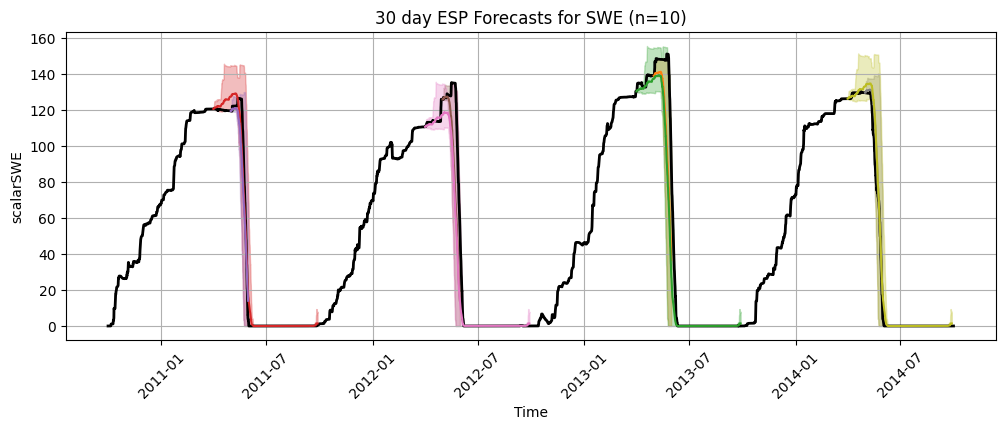

In [37]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path

def plot_ensemble_from_directories(base_file, output_dir, file_pattern, variable="IRFroutedRunoff", seg_id=1):
    # Function to process files from a directory
    dir_list = [x for x in output_dir.iterdir() if x.is_dir()]

    def load_ensemble_data(directory):
        ensemble_data = []
        for root, _, files in os.walk(directory):
            for file in files:
                if file_pattern in file:
                    file_path = os.path.join(root, file)
                    ds = xr.open_dataset(file_path)
                    if variable in ds:
                        try:
                            #var_data = ds[variable].where(ds['hruId'] == seg_id, drop=True)
                            var_data = ds[variable].isel(hru=seg_id)
                            ensemble_data.append(var_data)
                        except KeyError:
                            print(f"Segment ID '{seg_id}' not found in file {file_path}.")
                            continue
        return ensemble_data

    plt.figure(figsize=(12, 4))

    # Plot base file
    ds_base = xr.open_dataset(base_file)
    #var_data_base = ds_base[variable].where(ds_base['hruId'] == seg_id, drop=True).squeeze()
    var_data_base = ds_base[variable].isel(hru=seg_id)
    plt.plot(var_data_base['time'], var_data_base, label="Base File", color="black", linewidth=2)

    # Loop over each directory and process ensemble files
    for idx, directory in enumerate(dir_list):
        ensemble_data = load_ensemble_data(directory)

        if len(ensemble_data) > 0:
            # Stack ensemble data and calculate mean, max, and min across the ensemble dimension
            ensemble_stack = xr.concat(ensemble_data, dim="ensemble", coords='minimal', compat='override')
            ensemble_mean = ensemble_stack.mean(dim="ensemble").squeeze()
            ensemble_max = ensemble_stack.max(dim="ensemble").squeeze()
            ensemble_min = ensemble_stack.min(dim="ensemble").squeeze()
            color = f"C{idx+1}"  # Color cycling
            plt.plot(ensemble_mean['time'], ensemble_mean, label=f"Ensemble Mean - Dir {idx+1}", color=color)
            plt.fill_between(
                ensemble_mean['time'], ensemble_min, ensemble_max,
                color=color, alpha=0.3, label=f"Min/Max Envelope"
            )
        else:
            print(f"No files found in directory {directory} matching pattern '{file_pattern}'.")

    # Plot details
    plt.title(f'30 day ESP Forecasts for SWE (n=10)')
    plt.xlabel('Time')
    plt.xticks(rotation=45)
    plt.ylabel(variable)
    #plt.ylim(0,0.0000001)
    #plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
base_file = '/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/summa_output/Ross_base_timestep.nc'
output_dir = Path('/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/summa_output/Ross')
plot_ensemble_from_directories(base_file, output_dir, "summa", variable="scalarSWE", seg_id=40)

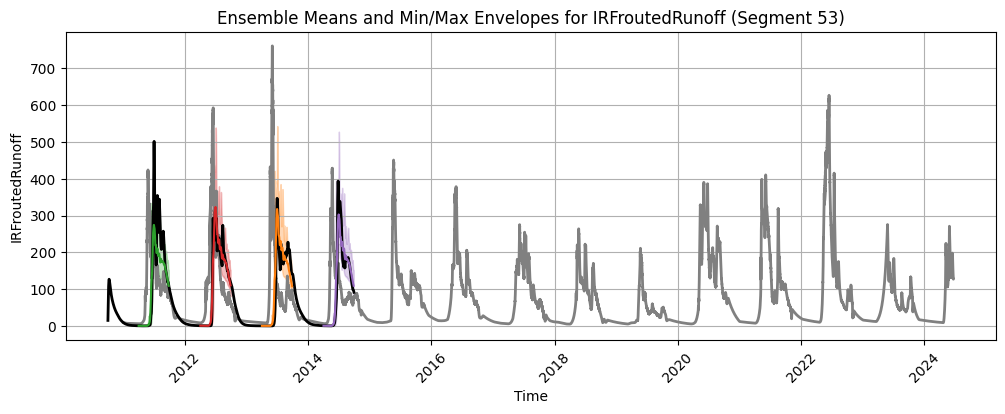

In [4]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
import pandas as pd

def plot_ensemble_from_directories(base_file, output_dir, file_pattern, variable="IRFroutedRunoff", seg_id=1,observations=None):
    
    dir_list = [x for x in output_dir.iterdir() if x.is_dir()]

    # Function to process files from a directory
    def load_ensemble_data(directory):
        ensemble_data = []
        for root, _, files in os.walk(directory):
            for file in files:
                if file_pattern in file:
                    file_path = os.path.join(root, file)
                    ds = xr.open_dataset(file_path)
                    if variable in ds:
                        try:
                            var_data = ds[variable].isel(seg=seg_id)
                            ensemble_data.append(var_data)
                        except KeyError:
                            print(f"Segment ID '{seg_id}' not found in file {file_path}.")
                            continue
        return ensemble_data

    plt.figure(figsize=(12, 4))

    #Read in observations
    if observations is not None:
        obs = pd.read_csv(observations)
        #read in datetime
        datetime = pd.to_datetime(obs['datetime'])
        plt.plot(datetime, obs['discharge_cms'], label="Observations", color="grey", linewidth=2)

    # Plot base file
    ds_base = xr.open_dataset(base_file)
    var_data_base = ds_base[variable].isel(seg=seg_id)
    plt.plot(ds_base['time'].values, var_data_base, label="Base File", color="black", linewidth=2)

    # Loop over each directory and process ensemble files
    for idx, directory in enumerate(dir_list):
        ensemble_data = load_ensemble_data(directory)

        if len(ensemble_data) > 0:
            # Stack ensemble data and calculate mean, max, and min across the ensemble dimension
            ensemble_stack = xr.concat(ensemble_data, dim="ensemble", coords='minimal', compat='override')
            ensemble_mean = ensemble_stack.mean(dim="ensemble").squeeze()
            ensemble_max = ensemble_stack.max(dim="ensemble").squeeze()
            ensemble_min = ensemble_stack.min(dim="ensemble").squeeze()
            color = f"C{idx+1}"  # Color cycling
            plt.plot(ensemble_mean['time'], ensemble_mean, label=f"Ensemble Mean - Dir {idx+1}", color=color)
            plt.fill_between(
                ensemble_mean['time'], ensemble_min, ensemble_max,
                color=color, alpha=0.3, label=f"Min/Max Envelope"
            )
        else:
            print(f"No files found in directory {directory} matching pattern '{file_pattern}'.")

    # Plot details
    plt.title(f'Ensemble Means and Min/Max Envelopes for {variable} (Segment {seg_id})')
    plt.xlabel('Time')
    plt.xticks(rotation=45)
    plt.ylabel(variable)
    # Clip x-axis to ignore the first month
    #plt.xlim(ds_base['time'], ds_base['time'].values[-1])
    #plt.ylim(0,10)
    #plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
base_file = '/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/mizuroute_output/Ross_base_routed.nc'
observations = '/Users/dcasson/Data/YukonProject/domain_Ross/shapefiles/streamflow/preprocessed/Ross_streamflow_processed.csv'
output_dir = Path('/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/mizuroute_output/Ross/')

 # Example directories
plot_ensemble_from_directories(base_file, output_dir, "mizuroute", variable="IRFroutedRunoff", seg_id=53, observations=observations)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/mizuroute_output/Ross'

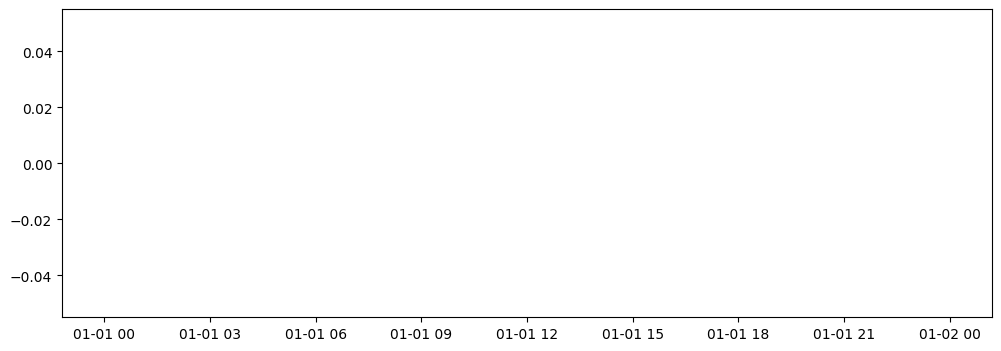

In [2]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
import pandas as pd

def plot_ensemble_from_directories(
    base_file,
    output_dir,
    file_pattern,
    variable="IRFroutedRunoff",
    seg_id=1,
    observations=None,
    start_time=None,
    end_time=None
):
    """
    Plots ensemble means and min/max envelopes of a specified variable from
    multiple directories against a base file and optional observations.
    
    Parameters
    ----------
    base_file : str or Path
        Path to the base NetCDF file.
    output_dir : Path
        Path to the parent directory containing sub-directories with ensemble NetCDF files.
    file_pattern : str
        Pattern to identify the NetCDF files (e.g., 'mizuroute').
    variable : str, optional
        Name of the variable to plot. Default is 'IRFroutedRunoff'.
    seg_id : int, optional
        Segment ID to select in the dataset. Default is 1.
    observations : str or Path, optional
        CSV file containing observations with columns ['datetime', 'discharge_cms'].
        Default is None (no observations).
    start_time : str or datetime-like, optional
        Start of the plotting period (inclusive). If None, plotting starts at the earliest time.
    end_time : str or datetime-like, optional
        End of the plotting period (inclusive). If None, plotting ends at the latest time.
    """

    # Convert start_time and end_time to pandas Timestamps if provided
    if start_time is not None:
        start_time = pd.to_datetime(start_time)
    if end_time is not None:
        end_time = pd.to_datetime(end_time)

    # Inner function to process files from a directory
    def load_ensemble_data(directory):
        ensemble_data = []
        for root, _, files in os.walk(directory):
            for file in files:
                if file_pattern in file:
                    file_path = os.path.join(root, file)
                    ds = xr.open_dataset(file_path)

                    # Only proceed if the variable is in the dataset
                    if variable in ds:
                        try:
                            var_data = ds[variable].isel(seg=seg_id)
                            
                            # If user specified start/end times, slice the time dimension
                            if start_time is not None or end_time is not None:
                                var_data = var_data.sel(time=slice(start_time, end_time))

                            ensemble_data.append(var_data)
                        except KeyError:
                            print(f"Segment ID '{seg_id}' not found in file {file_path}.")
                            continue
        return ensemble_data

    # Begin plotting
    plt.figure(figsize=(12, 4))

    # Read and plot observations if provided
    if observations is not None:
        obs = pd.read_csv(observations)
        obs['datetime'] = pd.to_datetime(obs['datetime'])
        
        # If user specified start/end times, subset observations
        if start_time is not None:
            obs = obs[obs['datetime'] >= start_time]
        if end_time is not None:
            obs = obs[obs['datetime'] <= end_time]
        
        #plt.plot(obs['datetime'], obs['discharge_cms'], label="Observations",
        #         color="grey", linewidth=2)

    # Plot base file
    ds_base = xr.open_dataset(base_file)
    var_data_base = ds_base[variable].isel(seg=seg_id)

    # If user specified start/end times, slice the time dimension
    if start_time is not None or end_time is not None:
        var_data_base = var_data_base.sel(time=slice(start_time, end_time))

    plt.plot(var_data_base['time'].values, var_data_base.values, 
             label="Base File", color="black", linewidth=2)

    # Collect all sub-directories in output_dir
    dir_list = [x for x in output_dir.iterdir() if x.is_dir()]

    # Loop over each directory and process ensemble files
    for idx, directory in enumerate(dir_list):
        ensemble_data = load_ensemble_data(directory)

        if len(ensemble_data) > 0:
            # Stack ensemble data and calculate statistics
            ensemble_stack = xr.concat(
                ensemble_data, dim="ensemble", coords='minimal', compat='override'
            )
            ensemble_mean = ensemble_stack.mean(dim="ensemble").squeeze()
            ensemble_max = ensemble_stack.max(dim="ensemble").squeeze()
            ensemble_min = ensemble_stack.min(dim="ensemble").squeeze()

            # Plot mean and envelope
            color = f"C{idx+1}"  # Use a simple color cycling
            plt.plot(ensemble_mean['time'], ensemble_mean,
                     label=f"Ensemble Mean - Dir {idx+1}", color=color)
            plt.fill_between(
                ensemble_mean['time'], ensemble_min, ensemble_max,
                color=color, alpha=0.3, label=f"Min/Max Envelope"
            )
        else:
            print(f"No files found in directory {directory} matching pattern '{file_pattern}'.")

    # Final plot details
    plt.title(f'Ensemble Means & Envelopes for {variable} (Segment {seg_id})')
    plt.xlabel('Time')
    plt.xticks(rotation=45)
    plt.ylabel(variable)
    plt.grid(True)

    # If the user specified a start and/or end time, set x-limits
    if start_time is not None or end_time is not None:
        plt.xlim(left=start_time, right=end_time)

    #plt.legend()
    plt.tight_layout()
    plt.show()


# Example usage:
if __name__ == "__main__":
    base_file = '/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/mizuroute_output/Ross_base_routed_backup.nc'
    observations = '/Users/dcasson/Data/YukonProject/domain_Ross/shapefiles/streamflow/preprocessed/Ross_streamflow_processed.csv'
    output_dir = Path('/Users/dcasson/Data/yukon_esp/ross_from_camille/model/output/mizuroute_output/Ross/')

    plot_ensemble_from_directories(
        base_file,
        output_dir,
        file_pattern="mizuroute",
        variable="IRFroutedRunoff",
        seg_id=53,
        observations=observations,
        start_time="2011-04-01",
        end_time="2012-07-30"
    )

In [26]:
nc = '/Users/dcasson/Data/yukon_esp/output/Chena_base_routed.nc'

ds = xr.open_dataset(nc)
print(ds)
ds['time'].values

<xarray.Dataset> Size: 6MB
Dimensions:          (time: 8759, seg: 45, hru: 45)
Coordinates:
  * time             (time) datetime64[ns] 70kB 2010-10-01 ... 2011-09-30T22:...
Dimensions without coordinates: seg, hru
Data variables:
    reachID          (seg) int32 180B ...
    basinID          (hru) int32 180B ...
    basRunoff        (time, hru) float32 2MB ...
    instRunoff       (time, seg) float32 2MB ...
    dlayRunoff       (time, seg) float32 2MB ...
    IRFroutedRunoff  (time, seg) float32 2MB ...
Attributes:
    mizuRoute-version:  v1.2.3
    gitBranch:          main-0-g0a62ee6
    gitHash:            0a62ee6185bdc9b99cd88ed5f15ea850602c43a2


<xarray.DataArray 'time' (time: 8759)> Size: 70kB
array(['2010-10-01T00:00:00.000000000', '2010-10-01T01:00:00.000000000',
       '2010-10-01T02:00:00.000000000', ..., '2011-09-30T20:00:00.000000000',
       '2011-09-30T21:00:00.000000000', '2011-09-30T22:00:00.000000000'],
      dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 70kB 2010-10-01 ... 2011-09-30T22:00:00
Attributes:
    long_name:  time